In [1]:
import os
import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import datetime as dt
import math

from pandas.plotting import autocorrelation_plot
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.preprocessing import MinMaxScaler
from common.utils import load_data, mape
from IPython.display import Image

%matplotlib inline

pd.options.display.float_format = '{:,.2f}'.format
np.set_printoptions(precision=2)
warnings.filterwarnings("ignore")

In [2]:
energy = load_data("./data")[['load']]
energy.head(10)

,load
2012-01-01 00:00:00,"2,698.00"
2012-01-01 01:00:00,"2,558.00"
2012-01-01 02:00:00,"2,444.00"
2012-01-01 03:00:00,"2,402.00"
2012-01-01 04:00:00,"2,403.00"
2012-01-01 05:00:00,"2,453.00"
2012-01-01 06:00:00,"2,560.00"
2012-01-01 07:00:00,"2,719.00"
2012-01-01 08:00:00,"2,916.00"
2012-01-01 09:00:00,"3,105.00"


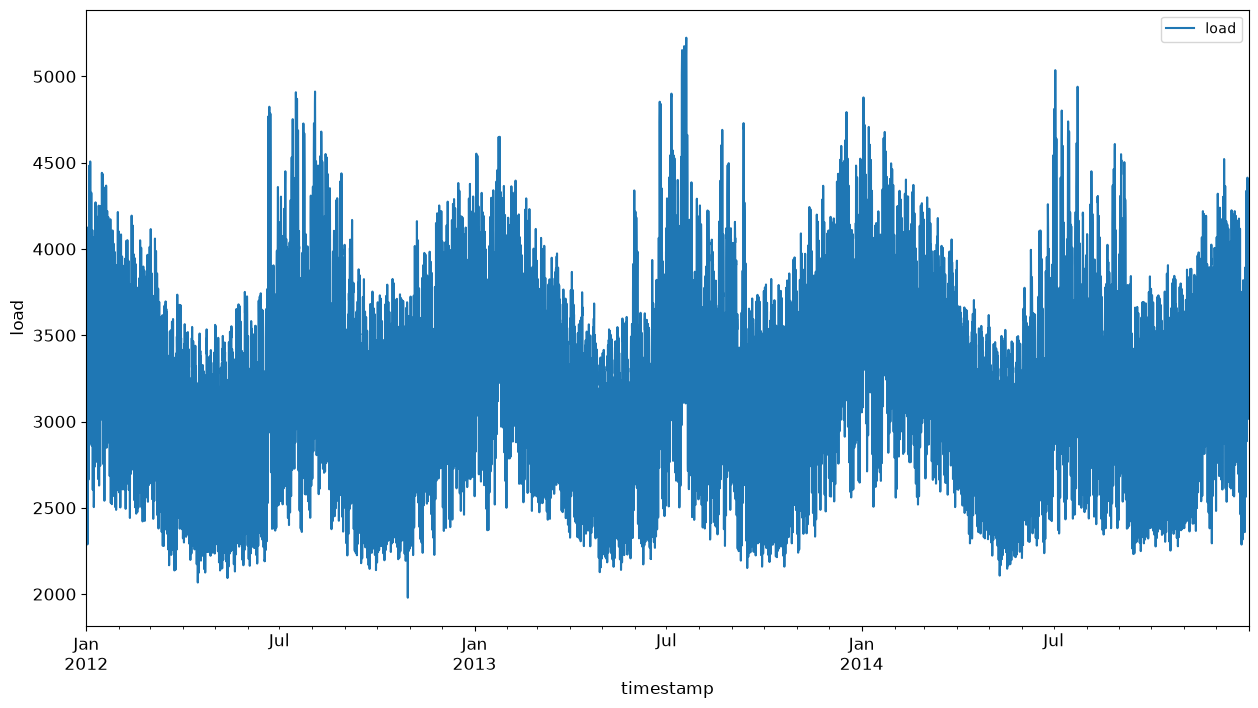

In [3]:
energy.plot(y='load', subplots=True, figsize=(15, 8),fontsize=12)
plt.xlabel('timestamp', fontsize=12)
plt.ylabel('load', fontsize=12)
plt.show()

In [4]:
train_start_dt = '2014-11-01 00:00:00'
test_start_dt = '2014-12-30 00:00:00'

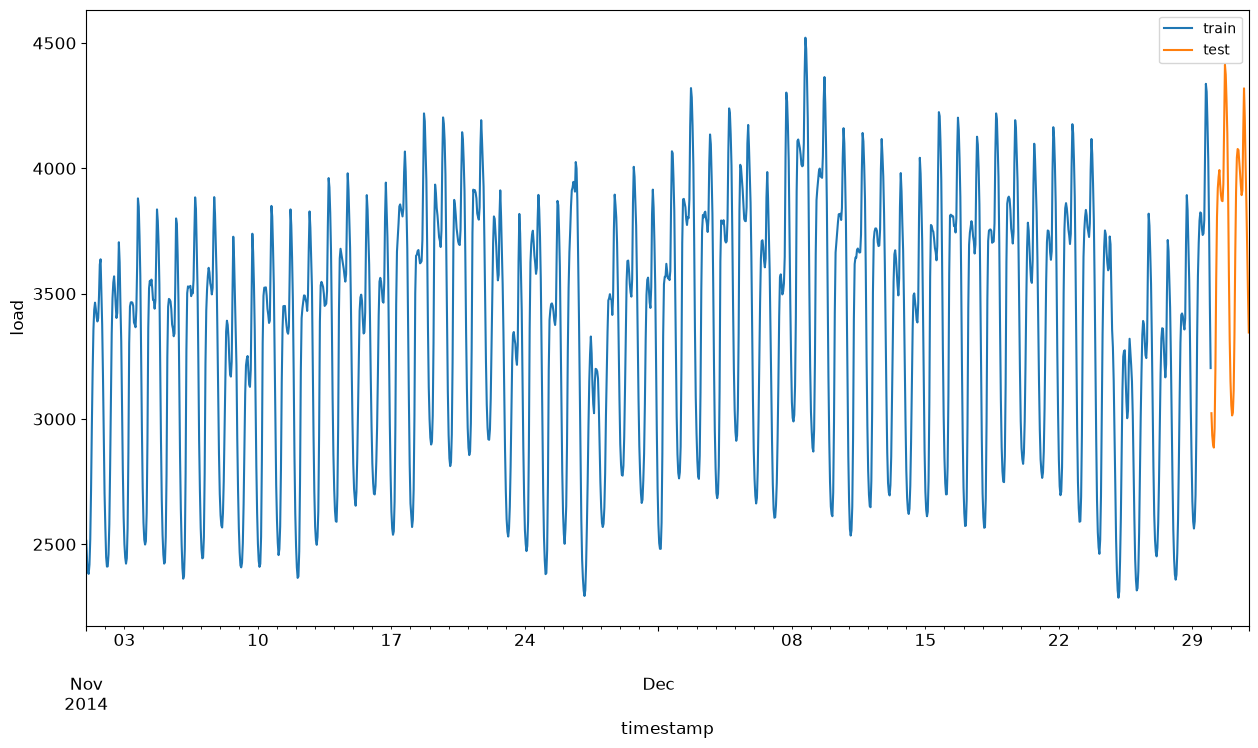

In [5]:
train_df = energy.copy()[(energy.index < test_start_dt) & (energy.index >= train_start_dt)][['load']]
test_df = energy.copy()[test_start_dt:][['load']]

train_df.rename(columns={'load':'train'}) \
.join(test_df.rename(columns={'load':'test'}), how='outer') \
.plot(y=['train', 'test'], figsize=(15, 8), fontsize=12)

plt.xlabel('timestamp', fontsize=12)
plt.ylabel('load', fontsize=12)
plt.show()

In [6]:
scaler = MinMaxScaler()
# scale the data to be in the range (0, 1).
train = train_df.copy()
train['load'] = scaler.fit_transform(train_df)

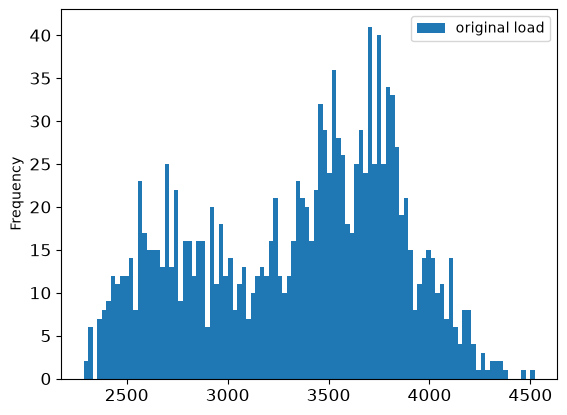

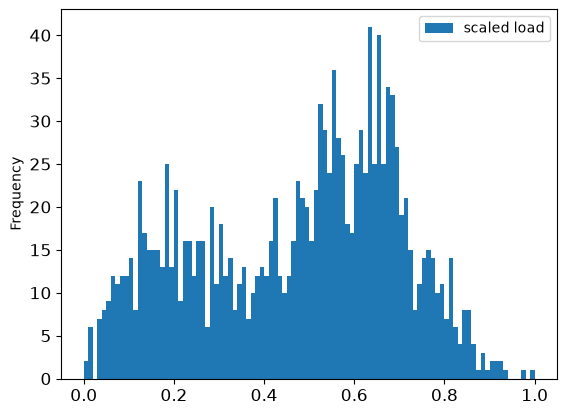

In [7]:
train_df.rename(columns={'load':'original load'}).plot.hist(bins=100,fontsize=12)
train.rename(columns={'load':'scaled load'}).plot.hist(bins=100,fontsize=12)
plt.show()

In [8]:
test = test_df.copy()
test['load'] = scaler.transform(test)

In [9]:
HORIZON = 3
print(f"Forecasting horizon: {HORIZON} hours")

order = (4, 1, 0)
seasonal_order = (1, 1, 0 , 24)
model = SARIMAX(endog=train, order=order, seasonal_order=seasonal_order)
results = model.fit()

print(results.summary())

Forecasting horizon: 3 hours
                                     SARIMAX Results                                      
Dep. Variable:                               load   No. Observations:                 1416
Model:             SARIMAX(4, 1, 0)x(1, 1, 0, 24)   Log Likelihood                3477.205
Date:                            Thu, 05 Nov 2026   AIC                          -6942.410
Time:                                    10:22:10   BIC                          -6910.984
Sample:                                11-01-2014   HQIC                         -6930.659
                                     - 12-29-2014                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.8398      0.016     52.517      0.000       0.808       0.871
ar.L2 

In [30]:
test_shifted = test.copy()

for t in range (1, HORIZON+1):
    test_shifted['load+' + str(t)] = test_shifted['load'].shift(-t, freq='h')
test_shifted = test_shifted.dropna(how='any')
test_shifted.head()

# BUG: TO BE FIX

,load,load+1,load+2,load+3
2014-12-30 00:00:00,0.33,0.29,0.27,0.27
2014-12-30 01:00:00,0.29,0.27,0.27,0.30
2014-12-30 02:00:00,0.27,0.27,0.30,0.41
2014-12-30 03:00:00,0.27,0.30,0.41,0.57
2014-12-30 04:00:00,0.30,0.41,0.57,0.68


In [12]:
%%time

import time

training_window = 720 # 30 days (720 hours) for training

train_ts = train['load']
test_ts = test_shifted

history = [x for x in train_ts]
history = history[(-training_window):]

predictions = list()

order = (2, 1, 0)
seasonal_order = (1, 1, 0, 24)

start = time.time()
for t in range (test_ts.shape[0]):
    model = SARIMAX(endog=history, order=order, seasonal_order=seasonal_order)
    model_fit = model.fit()
    yhat = model_fit.forecast(steps = HORIZON)
    predictions.append(yhat)
    obs = list(test_ts.iloc[t])

    # move the training window
    history.append(obs[0])
    history.pop(0)
    print(test_ts.index[t])
    print(f"{t+1}: predicted = {yhat}, expected = {obs}")

end = time.time()

print(f"training forecast spent {round(end - start, 2)} seconds")

2014-12-30 00:00:00
1: predicted = [0.32 0.29 0.28], expected = [0.32945389435989236, 0.2900626678603402, 0.2739480752014323]
2014-12-30 01:00:00
2: predicted = [0.3  0.29 0.3 ], expected = [0.2900626678603402, 0.2739480752014323, 0.26812891674127126]
2014-12-30 02:00:00
3: predicted = [0.27 0.28 0.32], expected = [0.2739480752014323, 0.26812891674127126, 0.3025962399283795]
2014-12-30 03:00:00
4: predicted = [0.28 0.32 0.42], expected = [0.26812891674127126, 0.3025962399283795, 0.40823634735899716]
2014-12-30 04:00:00
5: predicted = [0.3  0.39 0.54], expected = [0.3025962399283795, 0.40823634735899716, 0.5689346463742166]
2014-12-30 05:00:00
6: predicted = [0.4  0.55 0.66], expected = [0.40823634735899716, 0.5689346463742166, 0.6799462846911368]
2014-12-30 06:00:00
7: predicted = [0.57 0.68 0.75], expected = [0.5689346463742166, 0.6799462846911368, 0.7309758281110115]
2014-12-30 07:00:00
8: predicted = [0.68 0.75 0.8 ], expected = [0.6799462846911368, 0.7309758281110115, 0.75111906893

In [13]:
eval_df = pd.DataFrame(predictions, columns=['t+' + str(t) for t in range (1, HORIZON+ 1)])
eval_df['timestamp'] = test.index[0:len(test.index) - HORIZON + 1]
eval_df = pd.melt(eval_df, id_vars ='timestamp', value_name='prediction', var_name='h')
eval_df['actual'] = np.array(np.transpose(test_ts)).ravel()
eval_df[['prediction', 'actual']] = scaler.inverse_transform(eval_df[['prediction', 'actual']])
eval_df.head()

,timestamp,h,prediction,actual
0,2014-12-30 00:00:00,t+1,"3,008.83","3,023.00"
1,2014-12-30 01:00:00,t+1,"2,955.58","2,935.00"
2,2014-12-30 02:00:00,t+1,"2,900.11","2,899.00"
3,2014-12-30 03:00:00,t+1,"2,917.74","2,886.00"
4,2014-12-30 04:00:00,t+1,"2,946.78","2,963.00"


In [14]:
if HORIZON > 1:
    eval_df["APE"] = (eval_df['prediction'] - eval_df['actual']).abs() / eval_df['actual']
    print(eval_df.groupby('h')['APE'].mean())

h
t+1   0.01
t+2   0.01
t+3   0.02
Name: APE, dtype: float64


In [15]:
print('One step forecast MAPE: ', (mape(eval_df[eval_df['h'] == 't+1']['prediction'], eval_df[eval_df['h'] == 't+1']['actual']))*100, '%')
print('Multi step forecast MAPE: ', (mape(eval_df['prediction'], eval_df['actual'])*100, '%'))

One step forecast MAPE:  0.5573947951122443 %
Multi step forecast MAPE:  (np.float64(1.145612585629748), '%')


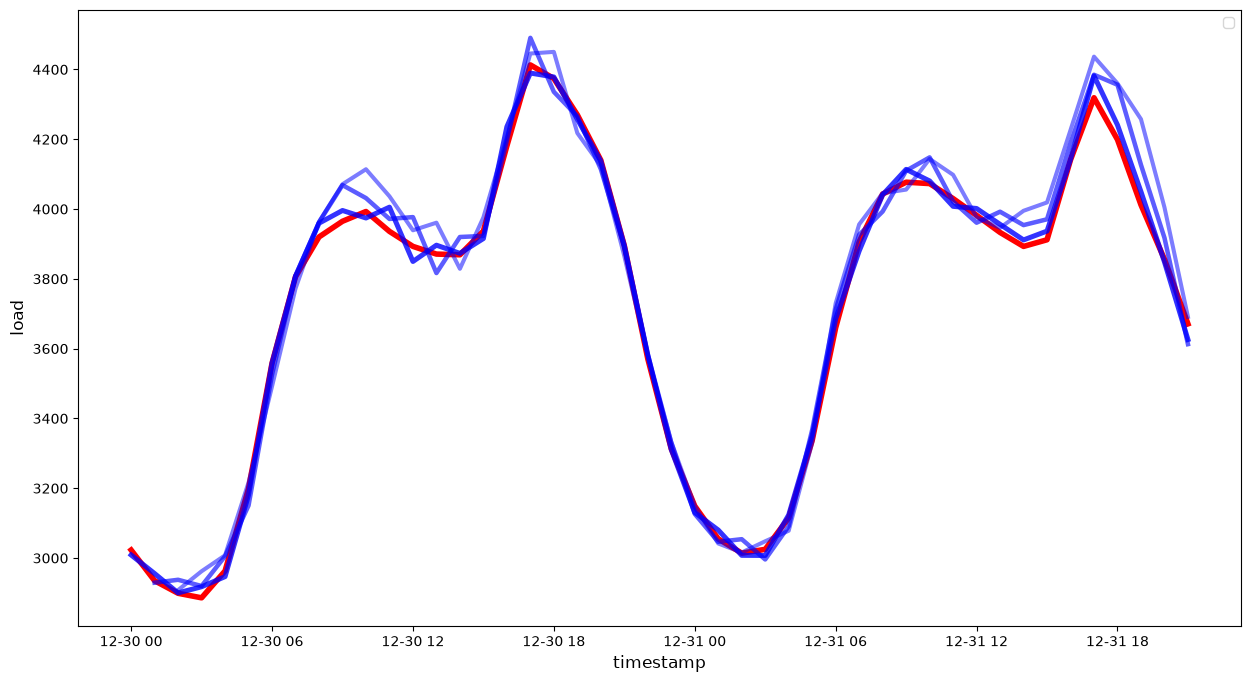

In [34]:
if HORIZON == 1:
    eval_df.plot(x='timestamp', y=['actual', 'prediction'], style=['r', 'b'], figsize=(15, 8))
else:
    plot_df = eval_df[(eval_df.h=='t+1')][['timestamp', 'actual']]
    for t in range(1, HORIZON+1):
        plot_df['t+'+str(t)] = eval_df[(eval_df.h=='t+'+str(t))]['prediction'].values

    fig = plt.figure(figsize=(15,8))
    ax = fig.add_subplot()
    ax.plot(plot_df['timestamp'], plot_df['actual'], color='red', linewidth=4.0)
    for t in range (1, HORIZON+1):
        x = plot_df['timestamp'][(t-1):]
        y = plot_df['t+'+str(t)][0:len(x)]
        ax.plot(x, y, color='blue', linewidth=4 * math.pow(.9, t), alpha=math.pow(0.8, t))
    ax.legend(loc='best')

plt.xlabel('timestamp', fontsize=12)
plt.ylabel('load', fontsize=12)
plt.show()